In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
df = pd.read_csv("tae.csv", header=None)
df.columns = ["Native_teacher","Instructor","Course","Semester","Class_size","Performance"]
print("Number of rows and columns:", df.shape)
display(df.head())

Number of rows and columns: (151, 6)


,Native_teacher,Instructor,Course,Semester,Class_size,Performance
0,1,23,3,1,19,3
1,2,15,3,1,17,3
2,1,23,3,2,49,3
3,1,5,2,2,33,3
4,2,7,11,2,55,3


In [3]:
df.info()
print("Missing values:")
print(df.isnull().sum())
print("Basic information:")
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 151 entries, 0 to 150
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Native_teacher  151 non-null    int64
 1   Instructor      151 non-null    int64
 2   Course          151 non-null    int64
 3   Semester        151 non-null    int64
 4   Class_size      151 non-null    int64
 5   Performance     151 non-null    int64
dtypes: int64(6)
memory usage: 7.2 KB
Missing values:
Native_teacher    0
Instructor        0
Course            0
Semester          0
Class_size        0
Performance       0
dtype: int64
Basic information:


,Native_teacher,Instructor,Course,Semester,Class_size,Performance
count,151.000000,151.000000,151.000000,151.000000,151.000000,151.000000
mean,1.807947,13.642384,8.105960,1.847682,27.867550,2.019868
std,0.395225,6.825779,7.023914,0.360525,12.893758,0.820327
min,1.000000,1.000000,1.000000,1.000000,3.000000,1.000000
25%,2.000000,8.000000,3.000000,2.000000,19.000000,1.000000
50%,2.000000,13.000000,4.000000,2.000000,27.000000,2.000000
75%,2.000000,20.000000,15.000000,2.000000,37.000000,3.000000
max,2.000000,25.000000,26.000000,2.000000,66.000000,3.000000


Performance
1    49
2    50
3    52
Name: count, dtype: int64


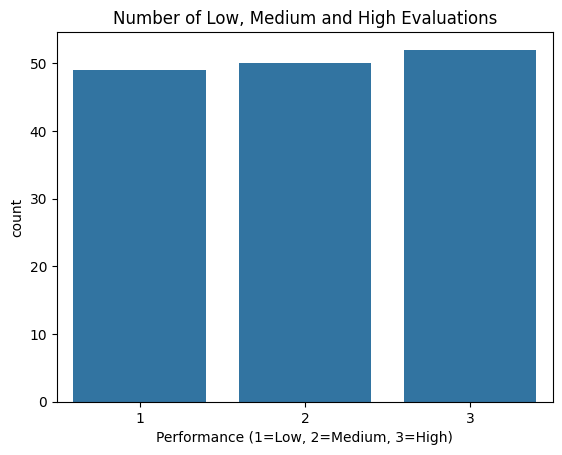

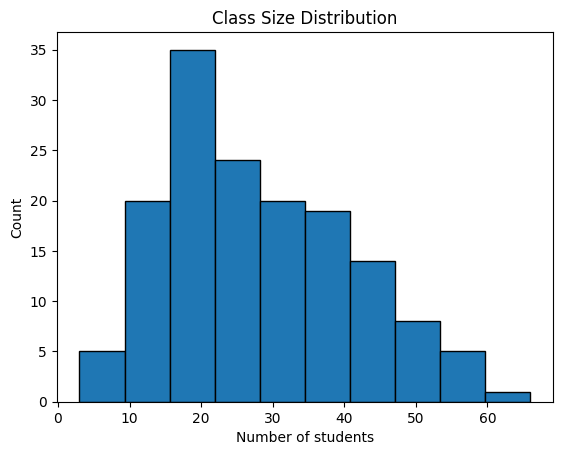

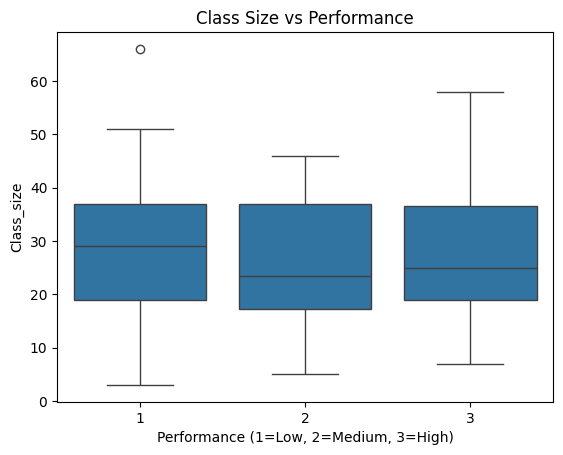

In [4]:
print(df["Performance"].value_counts().sort_index())
sns.countplot(data=df, x="Performance")
plt.title("Number of Low, Medium and High Evaluations")
plt.xlabel("Performance (1=Low, 2=Medium, 3=High)")
plt.show()
plt.hist(df["Class_size"], bins=10, edgecolor="black")
plt.title("Class Size Distribution")
plt.xlabel("Number of students")
plt.ylabel("Count")
plt.show()
sns.boxplot(data=df, x="Performance", y="Class_size")
plt.title("Class Size vs Performance")
plt.xlabel("Performance (1=Low, 2=Medium, 3=High)")
plt.show()

In [5]:
X = df.drop("Performance", axis=1)
y = df["Performance"]
categorical_columns = ["Native_teacher", "Instructor", "Course", "Semester"]
numeric_columns = ["Class_size"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 120
Testing rows: 31


In [6]:
for column in categorical_columns:
    X_train[column] = X_train[column].astype(str)
    X_test[column] = X_test[column].astype(str)
preparation = ColumnTransformer([("categories", OneHotEncoder(handle_unknown="ignore"), categorical_columns),("class_size", StandardScaler(), numeric_columns)])

In [7]:
models = {"Logistic Regression": LogisticRegression(max_iter=1000),"Decision Tree": DecisionTreeClassifier(random_state=42),"Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),"KNN": KNeighborsClassifier(n_neighbors=5)}
results = []
for name, model in models.items():
    pipeline = Pipeline([("preparation", preparation),("model", model)])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)
    results.append([name, accuracy])
    print(name, "accuracy:", round(accuracy * 100, 2), "%")
    models[name] = pipeline

Logistic Regression accuracy: 51.61 %
Decision Tree accuracy: 58.06 %
Random Forest accuracy: 67.74 %
KNN accuracy: 29.03 %


,Model,Accuracy
2,Random Forest,0.677419
1,Decision Tree,0.580645
0,Logistic Regression,0.516129
3,KNN,0.290323


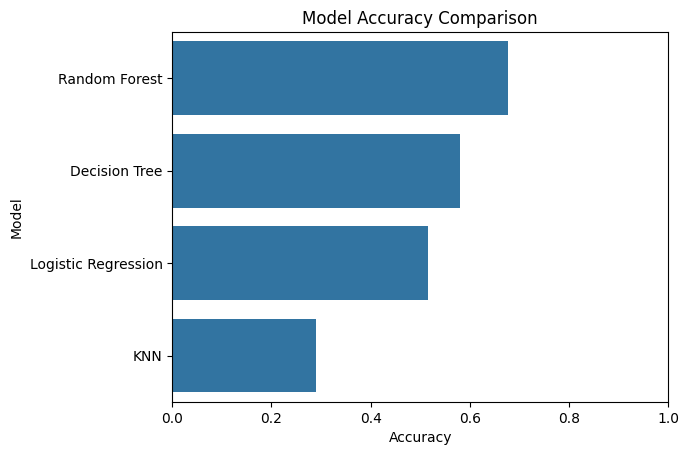

In [8]:
results_df = pd.DataFrame(results, columns=["Model", "Accuracy"])
results_df = results_df.sort_values("Accuracy", ascending=False)
display(results_df)
sns.barplot(data=results_df, x="Accuracy", y="Model")
plt.title("Model Accuracy Comparison")
plt.xlim(0, 1)
plt.show()

In [9]:
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]
print("Best model:", best_model_name)
final_predictions = best_model.predict(X_test)
print("Classification Report:")
print(classification_report(y_test,final_predictions,labels=[1, 2, 3],target_names=["Low", "Medium", "High"],zero_division=0))

Best model: Random Forest
Classification Report:
              precision    recall  f1-score   support

         Low       0.64      0.70      0.67        10
      Medium       0.60      0.60      0.60        10
        High       0.80      0.73      0.76        11

    accuracy                           0.68        31
   macro avg       0.68      0.68      0.68        31
weighted avg       0.68      0.68      0.68        31



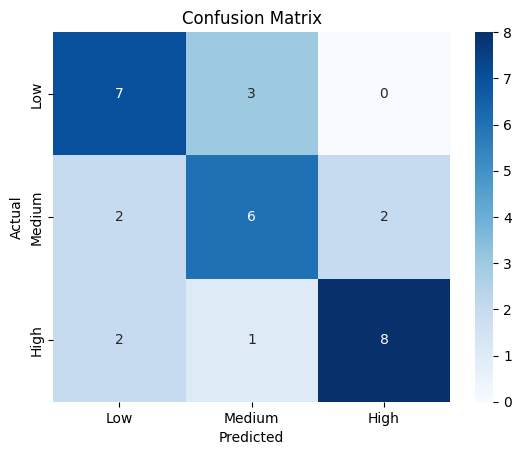

In [10]:
cm = confusion_matrix(y_test, final_predictions, labels=[1, 2, 3])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",xticklabels=["Low", "Medium", "High"],yticklabels=["Low", "Medium", "High"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [12]:
new_data = pd.DataFrame([{
    "Native_teacher": 1,
    "Instructor": 23,
    "Course": 3,
    "Semester": 2,
    "Class_size": 30 }])
for column in categorical_columns:
    new_data[column] = new_data[column].astype(str)
prediction = best_model.predict(new_data)[0]
performance_names = {1: "Low", 2: "Medium", 3: "High"}
print("Predicted performance:", performance_names[prediction])

Predicted performance: Low


# **Challenges**

1.   CSV file has no column names
2.   Instructor and course are category codes
3.   Dataset is small
4.   Features have different formats
5.   Need to compare models




# **Solutions**

1.   Added column names manually
2.   Converted them into categories using One-Hot Encoding
3.   Used an 80:20 train-test split and stratified sampling
4.   Used a simple preprocessing pipeline
5.   Compared four models using test accuracy



# **Conclusion**
In this project, I analysed the Teaching Assistant Evaluation dataset containing 151 records. I explored the data using simple graphs and prepared it for machine learning. I trained Logistic Regression, Decision Tree, Random Forest and KNN models. The best model in my test comparison was random forest, with an accuracy of 67.74% . The model predicts teaching evaluation categories as Low, Medium or High.